In [1]:
import warnings
import os 
from pathlib import Path
from natsort import natsort_keygen

import pandas as pd
import anndata as ad 
import numpy as np 
from dotenv import dotenv_values

import matplotlib.pyplot as plt
from scipy.cluster.hierarchy import dendrogram
import seaborn as sns

warnings.simplefilter(action='ignore', category=FutureWarning)

In [2]:
# Setting up filepaths from config
CONFIG = dotenv_values("config.env") 
DATADIR = Path(CONFIG['DATADIR'])

OUTDIR = DATADIR / "publication" / "Fig_05"
os.makedirs(OUTDIR, exist_ok=True)

SC_IN_FP = DATADIR / "9_objects" / "singlecell" / 'hypomap3d_singlecell_control.h5ad'

In [3]:

l1_color_map = {
    'Gl1-1 Glut': "#8c564b",
    'Gb1-2 GABA': "#aa40fc",
    'NN1-4 Astro-Epen': "#17becf",
    'NN1-1 OPC-Oligo': "#ffbb78",
    'NN1-2 Immune': "#aec7e8",
    'NN1-3 Vascular': "#98df8a" 
}


In [4]:
adata = ad.read_h5ad(SC_IN_FP, backed="r")

In [5]:
def build_custom_linkage(df, level_cols):
    """
    Build a custom linkage matrix Z from a DataFrame using specified hierarchical columns.
    Supports 2 levels of hierarchy.

    Parameters:
        df: pd.DataFrame
        level_cols (list of str): List of column names defining the hierarchy from top to bottom.

    Returns:
        tuple:
            Z (np.ndarray): linkage matrix for dendrogram.
            idx_to_label (dict): mapping from leaf index to bottom-level cluster label.
    """
    assert 2 <= len(level_cols), "Function supports 2 levels of hierarchy"
    
    # Drop duplicates and sort
    df = df[level_cols].drop_duplicates().astype(str)

    key = natsort_keygen()
    df = df.sort_values(
        by=level_cols,
        key=lambda col: col.map(key)
    )

    bottom_col = level_cols[-1]
    bottom_clusters = sorted(df[bottom_col].unique())
    n_leaves = len(bottom_clusters)

    cluster_sizes = {}
    Z = []
    current_idx = 0
    merge_map = {}

    # Map bottom level clusters to leaf indices
    bottom_to_idx = {name: i for i, name in enumerate(bottom_clusters)}
    idx_to_label = {i: name for i, name in enumerate(bottom_clusters)}
    cluster_sizes = {i: 1 for i in range(n_leaves)}
    current_idx = n_leaves

    # Recursive merging from bottom-up
    for level in reversed(range(1, len(level_cols))):  # Start from second last to top
        parent_col = level_cols[level - 1]
        child_col = level_cols[level]

        merge_map_level = {}
        for parent, group in df.groupby(parent_col):
            child_clusters = group[child_col].unique()
            leaves = [
                merge_map.get(child, bottom_to_idx.get(child))
                for child in child_clusters
            ]

            # Merge all clusters under this parent
            while len(leaves) > 1:
                a = leaves.pop()
                b = leaves.pop()
                size_a = cluster_sizes[a]
                size_b = cluster_sizes[b]
                new_size = size_a + size_b
                Z.append([a, b, 0.2 + 0.1 * level, new_size])  # Distance increases with hierarchy
                cluster_sizes[current_idx] = new_size
                leaves.append(current_idx)
                current_idx += 1

            merge_map_level[parent] = leaves[0]  # Store representative for parent cluster
        merge_map = merge_map_level

    # Final root merge if needed
    final_clusters = list(merge_map.values())
    while len(final_clusters) > 1:
        a = final_clusters.pop()
        b = final_clusters.pop()
        size_a = cluster_sizes[a]
        size_b = cluster_sizes[b]
        new_size = size_a + size_b
        Z.append([a, b, 1.0, new_size])
        cluster_sizes[current_idx] = new_size
        final_clusters.append(current_idx)
        current_idx += 1

    Z = np.array(Z)
    assert Z.shape[0] + 1 == n_leaves, f"Linkage matrix Z has incorrect shape: merges={Z.shape[0]}, leaves={n_leaves}"

    return Z, idx_to_label


In [6]:
def propagate_colors_to_deepest_level(df, level_cols, source_level_idx, cluster_color_map, default_color="#A0A0A0"):
    """
    Propagate colors from a specified source level to the deepest level in a hierarchy.

    Parameters:
        df (pd.DataFrame): DataFrame with hierarchical cluster levels as columns.
        level_cols (list of str): Ordered list of columns from top to bottom levels.
        source_level_idx (int): Index in level_cols of the source level (e.g., 0 for top).
        cluster_color_map (dict): Mapping from source level cluster names to colors.
        default_color (str): Default color to use if no mapping is found.

    Returns:
        dict: Mapping from deepest level cluster names to propagated colors.
    """
    assert 2 <= len(level_cols), "Supports 2 hierarchy levels"
    assert 0 <= source_level_idx < len(level_cols), "Invalid source level index"

    # Keep only relevant columns for mapping
    source_col = level_cols[source_level_idx]
    target_col = level_cols[-1]  # deepest level
    df_clean = df[[source_col, target_col]].drop_duplicates().astype(str)

    # Build mapping: deepest level → source level
    deep_to_source = dict(zip(df_clean[target_col], df_clean[source_col]))

    # Propagate color from source level to deepest
    deep_to_color = {
        deep: cluster_color_map.get(source, default_color)
        for deep, source in deep_to_source.items()
    }

    return deep_to_color


In [7]:
def plot_colored_dendrogram(Z, idx_to_label, leaf_label_to_color, linewidth=1.5, default_color="#000000", **kwargs):
    """
    Plots a dendrogram with colored branches based on leaf label to color mapping.

    Parameters:
        Z (np.ndarray): Linkage matrix.
        idx_to_label (dict): Mapping from leaf index to cluster label.
        leaf_label_to_color (dict): Mapping from cluster label to color.
        linewidth (float): Width of the dendrogram lines.
        default_color (str): Color to use when multiple colors are found under a branch.
        kwargs: Additional keyword arguments passed to scipy dendrogram.
    
    Returns:
        dict: The dendrogram object returned by scipy.cluster.hierarchy.dendrogram.
    """

    # Step 1: Build leaf index to color map
    leaf_colors = {
        i: leaf_label_to_color.get(idx_to_label[i], default_color)
        for i in idx_to_label
    }

    # Step 2: Helper to trace leaves under a node
    def trace_leaves(node):
        if node < len(idx_to_label):  # It's a leaf
            return {node}
        else:
            left = int(Z[node - len(idx_to_label), 0])
            right = int(Z[node - len(idx_to_label), 1])
            return trace_leaves(left) | trace_leaves(right)

    # Step 3: Determine color for each internal node
    link_colors = {}
    for i in range(Z.shape[0]):
        a, b = int(Z[i, 0]), int(Z[i, 1])
        leaves = trace_leaves(a) | trace_leaves(b)
        colors = {leaf_colors[leaf] for leaf in leaves}
        link_colors[i + len(idx_to_label)] = (
            colors.pop() if len(colors) == 1 else default_color
        )

    # Step 4: Plot with link color function
    with plt.rc_context({'lines.linewidth': linewidth}):
        dendro = dendrogram(
            Z,
            link_color_func=lambda k: link_colors.get(k, default_color),
            labels=[idx_to_label[i] for i in range(len(idx_to_label))],
            leaf_rotation=90,
            **kwargs
        )

    return dendro


In [8]:
level_cols = [f"L{i}_descr" for i in range(1,3)]

subclass_labelmat_NN = adata.obs.loc[adata.obs.L1_descr.str.contains("NN"), level_cols].drop_duplicates().astype(str)

key = natsort_keygen()
subclass_labelmat_NN = subclass_labelmat_NN.sort_values(
    by=level_cols,
    key=lambda col: col.map(key)
)

In [9]:
Z_subclass_NN, idx_to_l2_NN = build_custom_linkage(subclass_labelmat_NN, level_cols)
n_leaves_subclass_NN = subclass_labelmat_NN.L2_descr.nunique()

In [10]:
l2_to_color_NN = propagate_colors_to_deepest_level(
    subclass_labelmat_NN,
    level_cols=level_cols,
    source_level_idx=0, # propagate from 0 to last index
    cluster_color_map=l1_color_map
)


In [11]:
subclass_labelmat_NN.L2_descr.unique()

array(['NN2-1 Oligo_1', 'NN2-2 Oligo_2', 'NN2-3 OPC', 'NN2-4 Microglia_1',
       'NN2-5 Microglia_2', 'NN2-6 BAM', 'NN2-7 T cell', 'NN2-8 SMC',
       'NN2-9 Endo', 'NN2-10 Peri', 'NN2-11 VLMC', 'NN2-12 Astro',
       'NN2-13 Tanycyte', 'NN2-14 Ependymal'], dtype=object)

/tmp/ipykernel_935122/1204645120.py:11: UserWarning: Tight layout not applied. The bottom and top margins cannot be made large enough to accommodate all Axes decorations.
  plt.tight_layout()


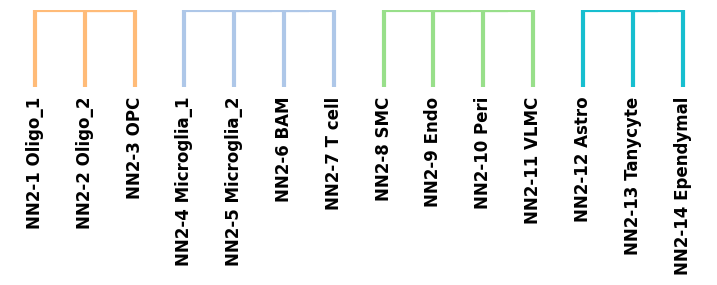

In [12]:

nn_l2_label_order = ['NN2-1 Oligo_1', 'NN2-2 Oligo_2', 'NN2-3 OPC', 
        'NN2-4 Microglia_1', 'NN2-5 Microglia_2', 'NN2-6 BAM', 'NN2-7 T cell', 'NN2-8 SMC',
       'NN2-9 Endo', 'NN2-10 Peri', 'NN2-11 VLMC', 'NN2-12 Astro',
       'NN2-13 Tanycyte', 'NN2-14 Ependymal']

plt.figure(figsize=(9, 1))
dendro_subclass_NN = plot_colored_dendrogram(Z_subclass_NN, idx_to_l2_NN, l2_to_color_NN, linewidth=3)


plt.xticks(fontweight='bold')
plt.tight_layout()
plt.ylim(0.2, 0.3)


plt.gca().invert_xaxis()
# Remove y-axis label
plt.ylabel("")

# Remove all spines (top, right, left, bottom)
sns.despine(left=True, right=True, top=True, bottom=True)

# Optionally remove y-axis ticks as well
plt.yticks([])

ax = plt.gca()
ax.set_xticklabels(nn_l2_label_order[::-1], rotation=90, fontsize=12)

plt.savefig(OUTDIR / f"dendro_nn_l2_with_l1_colors.pdf", format="pdf", dpi=300, bbox_inches="tight")

plt.show()
